# Phase 5 & 6 — Hybrid Stacked Ensemble
## Evaluation, Optimization & Deployment

> โหลดโมเดลที่ Fine-tune แล้วจาก `saved_models/` แล้วนำมาประเมินผล ปรับปรุง และสร้าง API

### Pipeline
```
Text Input
   ↓
[WangchanBERTa] [mBERT] [XLM-RoBERTa]  ← Base Models (fine-tuned)
   ↓ prob(7)      ↓ prob(7)   ↓ prob(7)
   └──────── Concat → Feature(21) ────┘
                  ↓
          [Random Forest]               ← Meta-Classifier
                  ↓
       Multi-label Emotion Output
```

## Phase 5: การวัดผลและปรับปรุง (Evaluation & Optimization)

In [1]:
# ติดตั้งไลบรารีที่จำเป็น (รันครั้งแรกเท่านั้น)
# !pip install torch transformers scikit-learn pandas numpy joblib matplotlib seaborn

import os, json, joblib, urllib.request
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    classification_report, hamming_loss,
    f1_score, multilabel_confusion_matrix
)
from sklearn.model_selection import train_test_split
import warnings; warnings.filterwarnings('ignore')

# โหลดและตั้งค่าฟอนต์ภาษาไทย (Sarabun)
font_dir = 'fonts'
font_path = os.path.join(font_dir, 'Sarabun-Regular.ttf')
if not os.path.exists(font_path):
    os.makedirs(font_dir, exist_ok=True)
    url = 'https://github.com/google/fonts/raw/main/ofl/sarabun/Sarabun-Regular.ttf'
    print('กำลังดาวน์โหลดฟอนต์ภาษาไทย (Sarabun)...')
    urllib.request.urlretrieve(url, font_path)

fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['axes.unicode_minus'] = False

print('✅ Import และตั้งค่าฟอนต์ภาษาไทยเรียบร้อย')

# Import ฟังก์ชันบันทึกผลการประเมินลง Markdown (.md)
import sys, gc
if '..' not in sys.path:
    sys.path.append('..')
from src.eval_logger import save_eval_report


✅ Import และตั้งค่าฟอนต์ภาษาไทยเรียบร้อย


In [2]:
# ==========================================
# 1. โหลดโมเดลจาก saved_models/
# ==========================================
SAVE_DIR = 'saved_models'
device   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'รันบน: {device}')

# โหลด Label Classes
with open(os.path.join(SAVE_DIR, 'label_classes.json'), encoding='utf-8') as f:
    LABEL_CLASSES = json.load(f)
NUM_LABELS = len(LABEL_CLASSES)
print(f'Labels ({NUM_LABELS}): {LABEL_CLASSES}')

# โหลด BERT Models ทั้ง 3
model_keys = ['wangchan', 'mbert', 'xlm_roberta']
tokenizers = {}
bert_models = {}

for key in model_keys:
    use_fast = False if key == 'wangchan' else True
    tokenizers[key] = AutoTokenizer.from_pretrained(
        os.path.join(SAVE_DIR, f'{key}_tokenizer'), use_fast=use_fast
    )
    bert_models[key] = AutoModelForSequenceClassification.from_pretrained(
        os.path.join(SAVE_DIR, f'{key}_model')
    ).to(device)
    bert_models[key].eval()
    print(f'  ✅ {key} โหลดสำเร็จ')

# โหลด Random Forest Meta-Classifier
rf_model = joblib.load(os.path.join(SAVE_DIR, 'random_forest_meta.joblib'))
print(f'\n✅ Random Forest โหลดสำเร็จ')

รันบน: cuda
Labels (7): ['Joy (ดีใจ)', 'Sadness (เศร้า)', 'Anger (โกรธ)', 'Fear (กลัว)', 'Surprise (ประหลาดใจ)', 'Neutral (เฉยๆ)', 'Disgust (ความขยะแขยง)']


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  ✅ wangchan โหลดสำเร็จ


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  ✅ mbert โหลดสำเร็จ


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  ✅ xlm_roberta โหลดสำเร็จ

✅ Random Forest โหลดสำเร็จ


In [3]:
# ==========================================
# 2. EmotionDataset & Helper Functions
# ==========================================
import ast

class EmotionDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts, self.labels, self.tokenizer, self.max_len = texts, labels, tokenizer, max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, i):
        enc = self.tokenizer(
            str(self.texts[i]),
            add_special_tokens=True, max_length=self.max_len,
            padding='max_length', truncation=True,
            return_attention_mask=True, return_tensors='pt'
        )
        return {
            'input_ids'     : enc['input_ids'].flatten(),
            'attention_mask': enc['attention_mask'].flatten(),
            'labels'        : torch.FloatTensor(self.labels[i])
        }

def get_probs(model, loader, device):
    """ดึง probability matrix จากโมเดล BERT"""
    all_probs = []
    with torch.no_grad():
        for batch in loader:
            out   = model(batch['input_ids'].to(device), batch['attention_mask'].to(device))
            probs = torch.sigmoid(out.logits).cpu().numpy()
            all_probs.extend(probs)
    return np.array(all_probs)

def make_loader(texts, labels, tokenizer, batch_size=32):
    return DataLoader(EmotionDataset(texts, labels, tokenizer), batch_size=batch_size, shuffle=False)

def encode_labels(tag_str, label2idx, n):
    vec = [0.0] * n
    for tag in ast.literal_eval(tag_str):
        if tag in label2idx: vec[label2idx[tag]] = 1.0
    return vec

print('✅ Helper functions พร้อมใช้งาน')

✅ Helper functions พร้อมใช้งาน


In [4]:
# ==========================================
# 3. โหลด Dataset และสร้าง Test Features
# ==========================================
df1 = pd.read_csv('clean-dataset/labeled_thai_clean_dataset_shopee.csv')
df2 = pd.read_csv('clean-dataset/labeled_thai_clean_dataset_X.csv')
df  = pd.concat([df1, df2], ignore_index=True).dropna(subset=['clean_text','emotion_tags'])

label2idx = {lbl: i for i, lbl in enumerate(LABEL_CLASSES)}
df['labels'] = df['emotion_tags'].apply(lambda x: encode_labels(x, label2idx, NUM_LABELS))

all_texts  = df['clean_text'].tolist()
all_labels = df['labels'].tolist()

# แบ่ง Train/Test เหมือน BaseModle (random_state=42)
train_texts, test_texts, train_labels, test_labels = train_test_split(
    all_texts, all_labels, test_size=0.2, random_state=42
)
print(f'Test set: {len(test_texts)} rows')

# ดึง Probability จากทั้ง 3 BERT บน Test Set
print('\nกำลังดึง probability จาก 3 โมเดล...')
test_feats = []
for key in model_keys:
    loader = make_loader(test_texts, test_labels, tokenizers[key])
    probs  = get_probs(bert_models[key], loader, device)
    test_feats.append(probs)
    print(f'  ✅ {key}: {probs.shape}')

X_test = np.concatenate(test_feats, axis=1)  # (N_test, 21)
y_test = np.array(test_labels)               # (N_test, 7)
print(f'\nFeature shape: {X_test.shape}')
# คืน GPU VRAM ทันทีหลังดึง probability เสร็จ (Random Forest ใช้แค่ CPU)
print('🧹 กำลังเคลียร์ BERT models ออกจาก GPU VRAM...')
del bert_models
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()
print('✅ คืน GPU VRAM สำเร็จ!')


Test set: 400 rows

กำลังดึง probability จาก 3 โมเดล...
  ✅ wangchan: (400, 7)
  ✅ mbert: (400, 7)
  ✅ xlm_roberta: (400, 7)

Feature shape: (400, 21)


In [5]:
# ==========================================
# 4. ประเมินผล Hybrid Ensemble
# ==========================================
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)  # list of arrays

print('=' * 55)
print('   ผลการประเมิน: Hybrid Stacked Ensemble')
print('=' * 55)
print(f'Hamming Loss         : {hamming_loss(y_test, y_pred):.4f}  (ต่ำ = ดี)')
print(f'F1 Micro             : {f1_score(y_test, y_pred, average="micro", zero_division=0):.4f}')
print(f'F1 Macro             : {f1_score(y_test, y_pred, average="macro", zero_division=0):.4f}')
print(f'F1 Weighted          : {f1_score(y_test, y_pred, average="weighted", zero_division=0):.4f}')
print()
print(classification_report(y_test, y_pred, target_names=LABEL_CLASSES, zero_division=0))
# บันทึกผลการประเมินลงไฟล์ Markdown (.md) ในโฟลเดอร์ results/ พร้อมอัปเดต SUMMARY.md
report_path = save_eval_report(
    y_true=y_test,
    y_pred=y_pred,
    target_names=LABEL_CLASSES,
    model_name="Hybrid Stacked Ensemble (Notebook 05)",
    hyperparams={
        "Base Models": "WangchanBERTa, mBERT, XLM-RoBERTa",
        "Meta Classifier": "RandomForest",
        "Test Size": len(y_test)
    },
    notes="การประเมินจาก Notebook 05_ensemble.ipynb",
    output_dir="../results" if os.path.exists("../results") else "results"
)


   ผลการประเมิน: Hybrid Stacked Ensemble
Hamming Loss         : 0.0875  (ต่ำ = ดี)
F1 Micro             : 0.7482
F1 Macro             : 0.3538
F1 Weighted          : 0.7619

                       precision    recall  f1-score   support

           Joy (ดีใจ)       0.95      0.90      0.92       342
      Sadness (เศร้า)       0.31      0.59      0.41        37
         Anger (โกรธ)       0.37      0.69      0.48        42
          Fear (กลัว)       0.00      0.00      0.00         7
 Surprise (ประหลาดใจ)       0.67      0.19      0.30        21
       Neutral (เฉยๆ)       0.00      0.00      0.00        17
Disgust (ความขยะแขยง)       0.33      0.40      0.36         5

            micro avg       0.73      0.77      0.75       471
            macro avg       0.38      0.40      0.35       471
         weighted avg       0.78      0.77      0.76       471
          samples avg       0.80      0.82      0.80       471



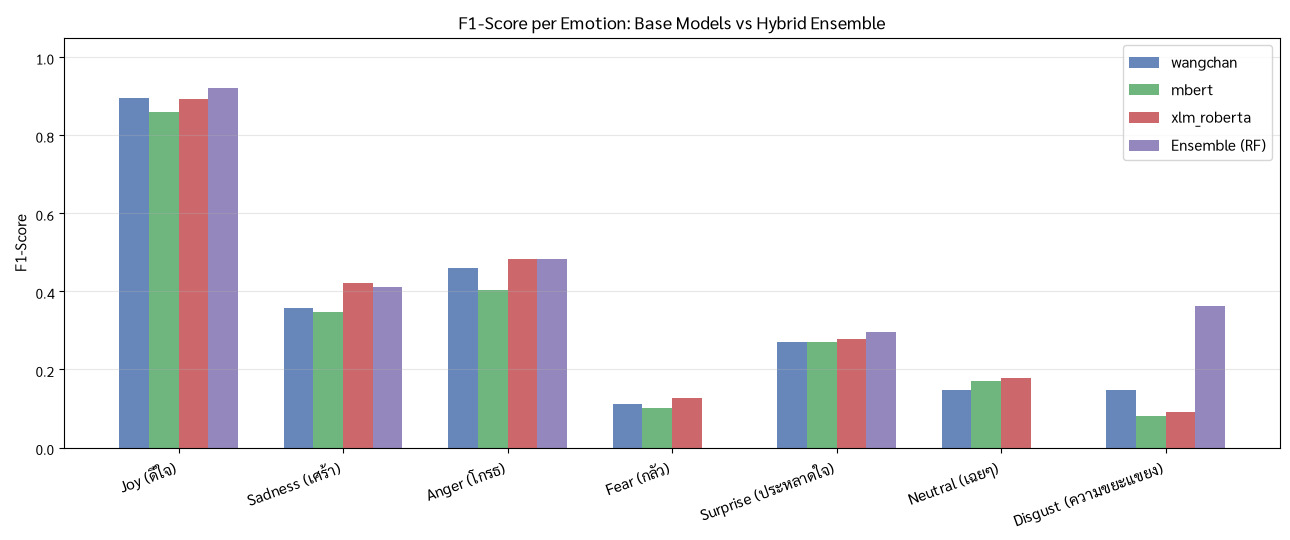

✅ บันทึกกราฟ → saved_models/f1_comparison.png


In [6]:
# ==========================================
# 5. กราฟเปรียบเทียบ F1-Score แต่ละ Emotion
# ==========================================
from sklearn.metrics import f1_score as f1

# ตั้งค่าฟอนต์ภาษาไทย
font_prop = fm.FontProperties(fname='fonts/Sarabun-Regular.ttf', size=11)
font_prop_title = fm.FontProperties(fname='fonts/Sarabun-Regular.ttf', size=13, weight='bold')

# เปรียบเทียบ: BERT แต่ละตัว vs Ensemble
results = {}

# ประเมิน BERT ทีละตัว (threshold 0.5)
for key, probs in zip(model_keys, test_feats):
    y_pred_bert = (probs >= 0.5).astype(int)
    results[key] = f1(y_test, y_pred_bert, average=None, zero_division=0)

# Ensemble
results['Ensemble (RF)'] = f1(y_test, y_pred, average=None, zero_division=0)

# วาดกราฟ
fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(NUM_LABELS)
width = 0.18
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

for i, (name, scores) in enumerate(results.items()):
    ax.bar(x + i * width, scores, width, label=name, color=colors[i], alpha=0.85)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(LABEL_CLASSES, rotation=20, ha='right', fontproperties=font_prop)
ax.set_ylabel('F1-Score', fontproperties=font_prop)
ax.set_title('F1-Score per Emotion: Base Models vs Hybrid Ensemble', fontproperties=font_prop_title)
ax.set_ylim(0, 1.05)
ax.legend(prop=font_prop)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('saved_models/f1_comparison.png', dpi=150)
plt.show()
print('✅ บันทึกกราฟ → saved_models/f1_comparison.png')


## Phase 6: การนำไปใช้งาน (Deployment & API)

In [7]:
# ==========================================
# 6. ฟังก์ชัน Predict สำหรับ Production
# ==========================================
def predict_emotion(text: str, threshold: float = 0.5) -> dict:
    """
    ทำนายอารมณ์จากข้อความภาษาไทย

    Args:
        text      : ข้อความที่ต้องการวิเคราะห์
        threshold : ค่า cutoff สำหรับ RF probability (default 0.5)

    Returns:
        dict ที่มี 'emotions' (list) และ 'probabilities' (dict)
    """
    # Tokenize + ดึง prob จาก 3 BERT
    feats = []
    dummy_label = [[0.0] * NUM_LABELS]  # placeholder

    for key in model_keys:
        loader = make_loader([text], dummy_label, tokenizers[key], batch_size=1)
        probs  = get_probs(bert_models[key], loader, device)
        feats.append(probs)

    X = np.concatenate(feats, axis=1)  # shape (1, 21)

    # Random Forest predict_proba → probability แต่ละ class
    rf_proba_list = rf_model.predict_proba(X)  # list ของ arrays
    # rf_proba_list[i] = array([[prob_neg, prob_pos]]) สำหรับ label i
    prob_pos = np.array([p[0][1] for p in rf_proba_list])  # shape (7,)

    # เลือก emotions ที่มี probability >= threshold
    predicted_emotions = [
        LABEL_CLASSES[i] for i, p in enumerate(prob_pos) if p >= threshold
    ]
    if not predicted_emotions:
        # fallback: เลือกอันที่ probability สูงสุด
        predicted_emotions = [LABEL_CLASSES[np.argmax(prob_pos)]]

    return {
        'text'         : text,
        'emotions'     : predicted_emotions,
        'probabilities': {lbl: round(float(p), 4) for lbl, p in zip(LABEL_CLASSES, prob_pos)}
    }

print('✅ predict_emotion() พร้อมใช้งาน')

# ทดสอบ
test_cases = [
    'ดีใจมากเลย ได้รับของแล้ว',
    'แอปห่วยมาก โกรธจริงๆ',
    'ส่งช้ามาก รอนานมากเลย เศร้าจัง',
    'โอเคนะ ใช้ได้อยู่',
]

print('\n=== ทดสอบ predict_emotion() ===')
for txt in test_cases:
    result = predict_emotion(txt)
    print(f'ข้อความ : {result["text"]}')
    print(f'อารมณ์  : {result["emotions"]}')
    probs_str = ', '.join(f'{k}: {v}' for k, v in result['probabilities'].items() if v > 0.1)
    print(f'Probs   : {probs_str}')
    print()

✅ predict_emotion() พร้อมใช้งาน

=== ทดสอบ predict_emotion() ===
ข้อความ : ดีใจมากเลย ได้รับของแล้ว
อารมณ์  : ['Joy (ดีใจ)']
Probs   : Joy (ดีใจ): 1.0

ข้อความ : แอปห่วยมาก โกรธจริงๆ
อารมณ์  : ['Anger (โกรธ)']
Probs   : Joy (ดีใจ): 0.36, Sadness (เศร้า): 0.29, Anger (โกรธ): 0.57, Fear (กลัว): 0.425, Neutral (เฉยๆ): 0.235

ข้อความ : ส่งช้ามาก รอนานมากเลย เศร้าจัง
อารมณ์  : ['Joy (ดีใจ)']
Probs   : Joy (ดีใจ): 0.995

ข้อความ : โอเคนะ ใช้ได้อยู่
อารมณ์  : ['Joy (ดีใจ)']
Probs   : Joy (ดีใจ): 0.9927



In [8]:
# ==========================================
# 7. สร้าง FastAPI (บันทึกเป็นไฟล์ app.py)
# ==========================================
api_code = '''
from fastapi import FastAPI
from pydantic import BaseModel
import subprocess, sys

# Auto-install dependencies
# pip install fastapi uvicorn torch transformers scikit-learn joblib

# Import ฟังก์ชันจาก notebook (หรือ copy predict_emotion มาไว้ที่นี่)
# from inference import predict_emotion  ← แนะนำให้แยก inference.py

app = FastAPI(
    title="Thai Emotion Detection API",
    description="Hybrid Stacked Ensemble: WangchanBERTa + mBERT + XLM-RoBERTa → Random Forest",
    version="1.0.0"
)

class TextRequest(BaseModel):
    text: str
    threshold: float = 0.5

@app.get("/")
def root():
    return {"message": "Thai Emotion Detection API is running!"}

@app.post("/predict")
def predict(req: TextRequest):
    result = predict_emotion(req.text, threshold=req.threshold)
    return result

# รัน: uvicorn app:app --reload --port 8000
'''

with open('app.py', 'w', encoding='utf-8') as f:
    f.write(api_code.strip())

print('✅ สร้าง app.py สำเร็จ')
print()
print('วิธีรัน API:')
print('  pip install fastapi uvicorn')
print('  uvicorn app:app --reload --port 8000')
print()
print('ทดสอบ API:')
print('  POST http://localhost:8000/predict')
print('  Body: {"text": "ดีใจมากเลย", "threshold": 0.5}')

✅ สร้าง app.py สำเร็จ

วิธีรัน API:
  pip install fastapi uvicorn
  uvicorn app:app --reload --port 8000

ทดสอบ API:
  POST http://localhost:8000/predict
  Body: {"text": "ดีใจมากเลย", "threshold": 0.5}


In [9]:
# ==========================================
# 8. Error Analysis — ดูตัวอย่างที่ทายผิด
# ==========================================
errors = []
for i, (true, pred, text) in enumerate(zip(y_test, y_pred, test_texts)):
    if not np.array_equal(true, pred):
        true_lbls = [LABEL_CLASSES[j] for j, v in enumerate(true) if v == 1]
        pred_lbls = [LABEL_CLASSES[j] for j, v in enumerate(pred) if v == 1]
        errors.append({'text': text, 'true': true_lbls, 'pred': pred_lbls})

print(f'ทายผิดทั้งหมด: {len(errors)} / {len(y_test)} ({len(errors)/len(y_test)*100:.1f}%)')
print(f'\n=== ตัวอย่าง Error 10 รายการแรก ===')
for err in errors[:10]:
    print(f'  ข้อความ : {err["text"][:60]}...')
    print(f'  จริง    : {err["true"]}')
    print(f'  ทำนาย   : {err["pred"]}')
    print()

# บันทึก error cases เป็น CSV
pd.DataFrame(errors).to_csv('saved_models/error_analysis.csv', index=False, encoding='utf-8-sig')
print('✅ บันทึก error_analysis.csv เรียบร้อย')

ทายผิดทั้งหมด: 115 / 400 (28.7%)

=== ตัวอย่าง Error 10 รายการแรก ===
  ข้อความ : อืม...
  จริง    : ['Joy (ดีใจ)']
  ทำนาย   : ['Joy (ดีใจ)', 'Anger (โกรธ)']

  ข้อความ : เวลาจะสั่งของพอใช้บัญชีตัวเองก็ขึ้นให้เปลี่ยนบัญชีอื่นเพราะใ...
  จริง    : ['Sadness (เศร้า)', 'Anger (โกรธ)']
  ทำนาย   : ['Joy (ดีใจ)']

  ข้อความ : เยี่ยม...
  จริง    : ['Joy (ดีใจ)']
  ทำนาย   : ['Joy (ดีใจ)', 'Neutral (เฉยๆ)']

  ข้อความ : รำคาณ...
  จริง    : ['Sadness (เศร้า)', 'Anger (โกรธ)']
  ทำนาย   : ['Joy (ดีใจ)']

  ข้อความ : ออกความเห็นแง่ลบหน่อยเดียวบล็อกที่ลงภาพโป๊ไม่ใส่อะไรกลับได้...
  จริง    : ['Sadness (เศร้า)', 'Anger (โกรธ)']
  ทำนาย   : ['Anger (โกรธ)']

  ข้อความ : จริงๆแอพมันดีมากเลยนะ แต่ที่ให้แค่ 4 ดาวเพราะ ระบบหลังบ้านชอ...
  จริง    : ['Joy (ดีใจ)', 'Anger (โกรธ)', 'Surprise (ประหลาดใจ)']
  ทำนาย   : ['Sadness (เศร้า)', 'Anger (โกรธ)', 'Disgust (ความขยะแขยง)']

  ข้อความ : สั่งแล้วค่าส่งไม่แพง...
  จริง    : ['Joy (ดีใจ)']
  ทำนาย   : ['Sadness (เศร้า)', 'Anger (โกรธ)']

  ข้อความ : รอ